In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path
from datetime import timedelta, timezone

src_path = Path().resolve().parents[1] / 'src'
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))


from sciezka_projektu import get_project_root

PROJECT_ROOT = get_project_root()

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "final"

df_r_pz1 = pd.read_parquet(DATA_PATH / "godzinowe-pz1-final.parquet")

df_rs_opady = pd.read_parquet(DATA_PATH / "suma_opadow.parquet")
display(df_r_pz1)
df = pd.DataFrame()
df["Data_czas"] = df_r_pz1.index
df = df.set_index("Data_czas")
df["ilosc"] = df_r_pz1['energia_kwh']
df

,przepompowano_m3,energia_kwh,opad_mm
Data_czas,,,
2024-01-02 00:00:00+01:00,NaN,12.745,NaN
2024-01-02 01:00:00+01:00,NaN,11.878,NaN
2024-01-02 02:00:00+01:00,NaN,10.303,NaN
2024-01-02 03:00:00+01:00,NaN,7.653,NaN
2024-01-02 04:00:00+01:00,NaN,6.596,NaN
...,...,...,...
2024-12-12 19:00:00+01:00,136.7,NaN,NaN
2024-12-12 20:00:00+01:00,161.6,NaN,NaN
2024-12-12 21:00:00+01:00,196.5,NaN,NaN


,ilosc
Data_czas,
2024-01-02 00:00:00+01:00,12.745
2024-01-02 01:00:00+01:00,11.878
2024-01-02 02:00:00+01:00,10.303
2024-01-02 03:00:00+01:00,7.653
2024-01-02 04:00:00+01:00,6.596
...,...
2024-12-12 19:00:00+01:00,NaN
2024-12-12 20:00:00+01:00,NaN
2024-12-12 21:00:00+01:00,NaN


In [18]:
%load_ext autoreload
%autoreload 2

from models.final.przepompowanie_rybnik_dane import przygotuj_dane_przepompowanie

X_pz1,y_pz1, X_pnb1, y_pnb1 = przygotuj_dane_przepompowanie()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [35]:
%load_ext autoreload
%autoreload 2
X = X_pz1
y = y_pz1

train_end = int(len(X) * 0.7)

X_train = X.iloc[:train_end]
X_test = X.iloc[train_end:]

y_train = y.iloc[:train_end]
y_test = y.iloc[train_end:]

#print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
#print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
#print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [36]:
# CATBOOST
from catboost import CatBoostRegressor

cb_median = CatBoostRegressor(
    loss_function = "MAE",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_median.fit(X_train, y_train)

cb_q97 = CatBoostRegressor(
    loss_function = "Quantile:alpha=0.97",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_q97.fit(X_train, y_train)

y_pred_val = cb_median.predict(X_test)
q_val = cb_q97.predict(X_test)

Godziny ponad normę: 30 z 2055


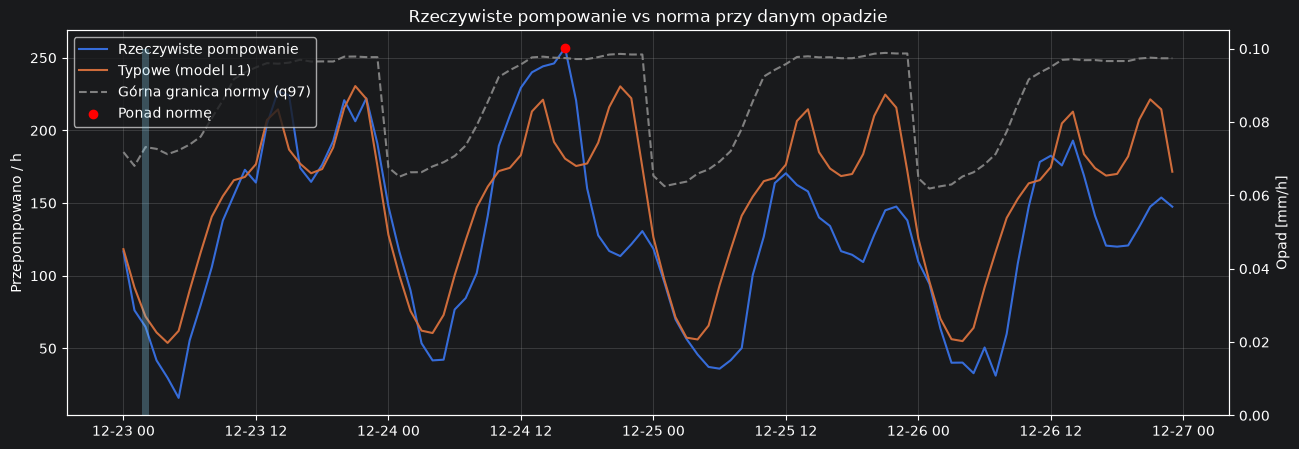

In [38]:
results_val = pd.DataFrame({
    "rzeczywiste": y_test,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_test["opad_0h"],
    "opad_6h": X_test["opad_6h"],
}, index=y_test.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2024-12-23":"2024-12-26"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [39]:
# Alarm, gdy rzeczywiste pompowanie przekracza Q97
results_val["alarm"] = results_val["anomaly"]

# Nadwyżka względem typowej prognozy pogodowej
results_val["nadwyzka"] = (
    results_val["rzeczywiste"] - results_val["prognoza"]
).clip(lower=0)

print("Liczba godzin alarmowych:", results_val["alarm"].sum())

print(
    "Suma nadwyżek w godzinach alarmowych:",
    round(results_val.loc[results_val["alarm"], "nadwyzka"].sum(), 2)
)

Liczba godzin alarmowych: 30
Suma nadwyżek w godzinach alarmowych: 2495.17


In [40]:
anomalie = results_val[results_val["alarm"]].copy()

#kiedy wystąpiły alarmy, jaka była nadwyżka i czy padało
display(anomalie[["rzeczywiste", "prognoza", "q97", "nadwyzka", "ponad_q97", "opad", "opad_6h"]])

,rzeczywiste,prognoza,q97,nadwyzka,ponad_q97,opad,opad_6h
Data_czas,,,,,,,
2024-10-06 11:00:00+01:00,274.3,188.030471,241.811874,86.269529,32.488126,0.0,0.0
2024-10-07 14:00:00+01:00,252.6,209.724166,239.921783,42.875834,12.678217,0.0,0.0
2024-10-08 14:00:00+01:00,247.4,216.260902,242.846535,31.139098,4.553465,0.0,0.0
2024-10-10 10:00:00+01:00,338.7,164.592352,228.666694,174.107648,110.033306,0.0,0.0
2024-10-12 12:00:00+01:00,252.0,215.590155,250.168739,36.409845,1.831261,0.0,0.0
2024-10-14 08:00:00+01:00,251.2,143.018466,192.354898,108.181534,58.845102,0.0,0.0
2024-10-18 14:00:00+01:00,245.0,219.301245,241.914144,25.698755,3.085856,0.0,0.0
2024-10-22 16:00:00+01:00,291.3,164.514529,242.926294,126.785471,48.373706,0.0,0.0
2024-10-31 00:00:00+01:00,165.5,88.064162,152.180517,77.435838,13.319483,0.0,0.0


In [41]:
from sklearn.metrics import mean_absolute_error
# Ewaluacja na zbiorze testowym
y_pred_test = cb_median.predict(X_test)
q_test = cb_q97.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred_test)
odsetek_test = (y_test > q_test).mean() * 100

print("MAE TEST:", round(mae_test, 2))
prof = y_train.groupby(y_train.index.hour).median()
base_test = prof.reindex(y_test.index.hour).values
print("MAE baseline:", round(mean_absolute_error(y_test, base_test), 2))
print("Przekroczenia Q97 TEST:", round(odsetek_test, 2), "%")
print("Liczba alarmów TEST:", int((y_test > q_test).sum()))


MAE TEST: 26.67
MAE baseline: 25.63
Przekroczenia Q97 TEST: 1.46 %
Liczba alarmów TEST: 30


In [42]:
#SHAP
from SHAP import generate_shap_from_tree

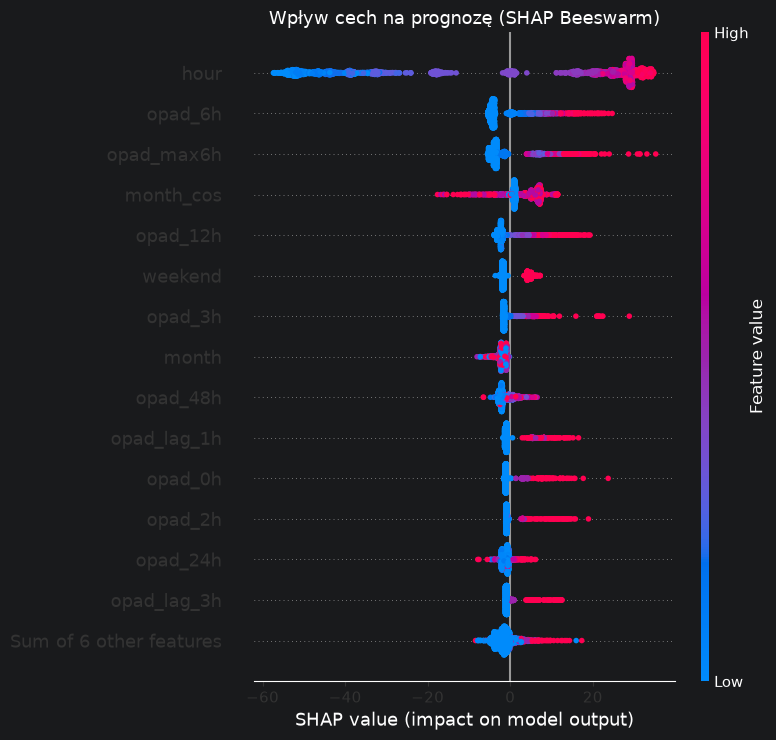

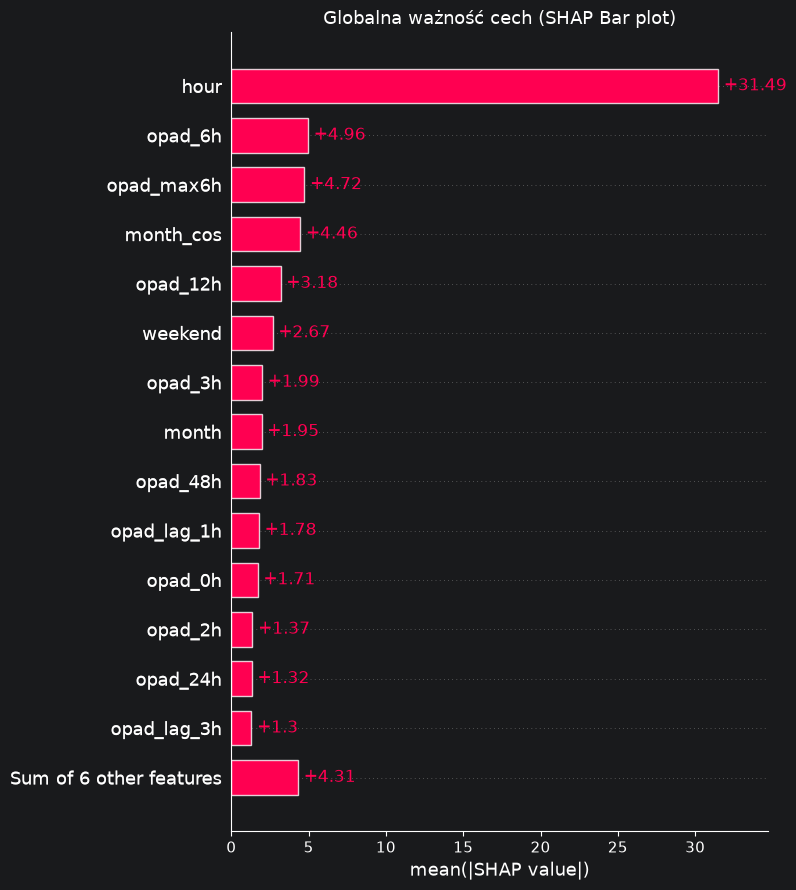

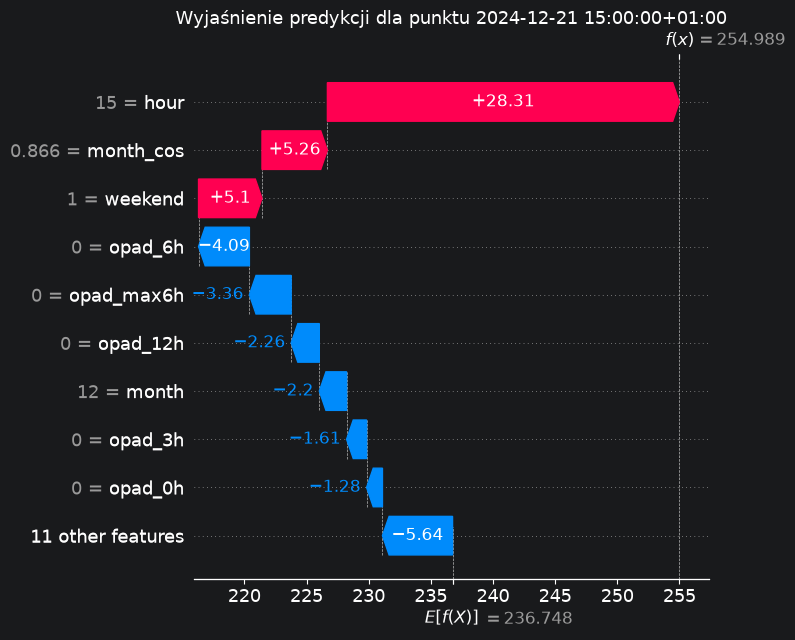

In [43]:
generate_shap_from_tree(cb_q97,X_test,date_with_time="2024-12-21 15:00:00")

# OPTYMALIZACJA OPTUNA

In [44]:

import optuna

train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

import numpy as np
import optuna


# STROJENIE MODELU MEDIANOWEGO (cb_median)
def objective_median(trial):
    params = {
        'loss_function': 'MAE',
        'eval_metric': 'MAE',
        'iterations': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 5.0),
        'task_type': 'CPU',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params, early_stopping_rounds=40)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

    preds = model.predict(X_val)
    mae = np.mean(np.abs(y_val - preds))
    return mae

study_median = optuna.create_study(direction="minimize")
study_median.optimize(objective_median, n_trials=40)
print("Najlepsze parametry dla Median:", study_median.best_params)


# STROJENIE MODELU KWANTYLOWEGO (cb_q97)
def pinball_loss(y_true, y_pred, alpha=0.97):
    err = y_true - y_pred
    return np.mean(np.maximum(alpha * err, (alpha - 1.0) * err))

def objective_q97(trial):
    params = {
        'loss_function': 'Quantile:alpha=0.97',
        'eval_metric': 'Quantile:alpha=0.97',
        'iterations': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 5.0),
        'task_type': 'CPU',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params, early_stopping_rounds=40)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

    q_preds = model.predict(X_val)

    #Błąd Pinball
    loss = pinball_loss(y_val, q_preds, alpha=0.97)

    #Kara za uciekanie od Coverage = 97%
    empirical_coverage = np.mean(y_val <= q_preds)
    coverage_penalty = np.abs(empirical_coverage - 0.97) * 5.0

    return loss + coverage_penalty

study_q97 = optuna.create_study(direction="minimize")
study_q97.optimize(objective_q97, n_trials=40)
print("Najlepsze parametry dla Q97:", study_q97.best_params)

[I 2026-10-28 10:49:56,052] A new study created in memory with name: no-name-4ecffdee-25c4-452d-8817-a94c0741b0ac
[I 2026-10-28 10:49:56,312] Trial 0 finished with value: 24.920404620674596 and parameters: {'learning_rate': 0.053129989640266745, 'depth': 4, 'l2_leaf_reg': 10.3821393956734, 'random_strength': 1.5746378220527049}. Best is trial 0 with value: 24.920404620674596.
[I 2026-10-28 10:49:56,771] Trial 1 finished with value: 22.82527004559941 and parameters: {'learning_rate': 0.045946342936672234, 'depth': 7, 'l2_leaf_reg': 18.190088382700395, 'random_strength': 0.19116958145529392}. Best is trial 1 with value: 22.82527004559941.
[I 2026-10-28 10:49:57,955] Trial 2 finished with value: 24.056098727108424 and parameters: {'learning_rate': 0.028925977337296675, 'depth': 6, 'l2_leaf_reg': 6.740920413230626, 'random_strength': 4.241052924247259}. Best is trial 1 with value: 22.82527004559941.
[I 2026-10-28 10:49:58,519] Trial 3 finished with value: 24.4370851637752 and parameters: {

Najlepsze parametry dla Median: {'learning_rate': 0.07995042115380327, 'depth': 8, 'l2_leaf_reg': 18.75039905989283, 'random_strength': 0.21060313808042583}


[I 2026-10-28 10:50:31,605] Trial 0 finished with value: 3.071782504780833 and parameters: {'learning_rate': 0.011239997641775011, 'depth': 8, 'l2_leaf_reg': 14.22942204531535, 'random_strength': 2.065199655840174}. Best is trial 0 with value: 3.071782504780833.
[I 2026-10-28 10:50:36,269] Trial 1 finished with value: 3.023291319038983 and parameters: {'learning_rate': 0.011856606603434816, 'depth': 8, 'l2_leaf_reg': 7.68369966230951, 'random_strength': 4.986814041844766}. Best is trial 1 with value: 3.023291319038983.
[I 2026-10-28 10:50:36,763] Trial 2 finished with value: 3.1442240361228837 and parameters: {'learning_rate': 0.09801625503820799, 'depth': 4, 'l2_leaf_reg': 11.607354809330616, 'random_strength': 2.162049652645848}. Best is trial 1 with value: 3.023291319038983.
[I 2026-10-28 10:50:37,585] Trial 3 finished with value: 3.13241990122164 and parameters: {'learning_rate': 0.02621887105767558, 'depth': 4, 'l2_leaf_reg': 7.195589043045918, 'random_strength': 2.167115571139266

Najlepsze parametry dla Q97: {'learning_rate': 0.07488632367001277, 'depth': 6, 'l2_leaf_reg': 15.35559055725768, 'random_strength': 0.00744185455931932}


In [45]:
print("Najlepszy wynik median (MAE):", study_median.best_value)
print("Najlepsze parametry median:", study_median.best_params)

print("Najlepszy wynik q97 (MAE):", study_q97.best_value)
print("Najlepsze parametry q97:", study_q97.best_params)

Najlepszy wynik median (MAE): 22.105181923068137
Najlepsze parametry median: {'learning_rate': 0.07995042115380327, 'depth': 8, 'l2_leaf_reg': 18.75039905989283, 'random_strength': 0.21060313808042583}
Najlepszy wynik q97 (MAE): 2.886717034045187
Najlepsze parametry q97: {'learning_rate': 0.07488632367001277, 'depth': 6, 'l2_leaf_reg': 15.35559055725768, 'random_strength': 0.00744185455931932}


In [46]:
# CATBOOST
from catboost import CatBoostRegressor


check_median = CatBoostRegressor(
    **study_median.best_params,
    loss_function="MAE",
    eval_metric="MAE",
    iterations=2500,
    early_stopping_rounds=50,
    task_type="CPU",
    thread_count=-1,
    random_seed=42,
    verbose=100
)
check_median.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True
)


best_trees = check_median.get_best_iteration()
print(f"Optymalna liczba iteracji: {best_trees}")

0:	learn: 52.5254632	test: 44.6702635	best: 44.6702635 (0)	total: 21.2ms	remaining: 52.9s
100:	learn: 19.2440989	test: 22.2023516	best: 22.1051807 (83)	total: 435ms	remaining: 10.3s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 22.10518067
bestIteration = 83

Shrink model to first 84 iterations.
Optymalna liczba iteracji: 83


In [47]:
from catboost import CatBoostRegressor


check_q97 = CatBoostRegressor(
    **study_q97.best_params,
    loss_function="Quantile:alpha=0.97",
    eval_metric="Quantile:alpha=0.97",
    iterations=2500,
    early_stopping_rounds=50,
    task_type="CPU",
    thread_count=-1,
    random_seed=42,
    verbose=0
)

check_q97.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True)

best_trees_q97 = check_q97.get_best_iteration()
q_test = check_q97.predict(X_test)
print(f"Optymalna liczba iteracji dla q97 to: {best_trees_q97}")
odsetek_test = np.mean(y_test.to_numpy() > q_test.ravel()) * 100

print("MAE TEST:", round(mae_test, 2))
prof = y_train.groupby(y_train.index.hour).median()
base_test = prof.reindex(y_test.index.hour).values
print("MAE baseline:", round(mean_absolute_error(y_test, base_test), 2))
print("Przekroczenia Q97 TEST:", round(odsetek_test, 2), "%")

Optymalna liczba iteracji dla q97 to: 310
MAE TEST: 26.67
MAE baseline: 26.83
Przekroczenia Q97 TEST: 1.95 %
